In [15]:
from em1d.experiment import *
import numpy as np
t0 = np.geomspace(1e-6, 1e-2, 31)
sq = Loop.square(40)
rx = Receiver()
t = np.array([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = np.array([0, 1, 1, 0])
waveform = Waveform(t, wv)
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

fwr0 = Forward(sq, rx, torch.from_numpy(t0))
fwr1 = Forward(sq, rx, torch.from_numpy(t0), tolerance=1e-6)
rho   = 10**(np.random.randn(6)+1)
thick = np.geomspace(2, 50, len(rho)-1)
sigma = torch.from_numpy(1./rho)
thick = torch.from_numpy(thick)
dbdt = fwr0(sigma, thick)

tmin, tmax tensor(1.0000e-06, dtype=torch.float64) tensor(0.0100, dtype=torch.float64) None
tmin, tmax tensor(1.0000e-06, dtype=torch.float64) tensor(0.0100, dtype=torch.float64) None


In [16]:
%%timeit
dbdt = fwr0(sigma, thick)

803 ms ± 131 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [17]:
%%timeit
dbdt = fwr1(sigma, thick)

fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
fraction of coefficients  0.4490644490644491
400 ms ± 38.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [18]:
dbdt1 = fwr1(sigma, thick)
dbdt0 = fwr0(sigma, thick)

fraction of coefficients  0.4490644490644491


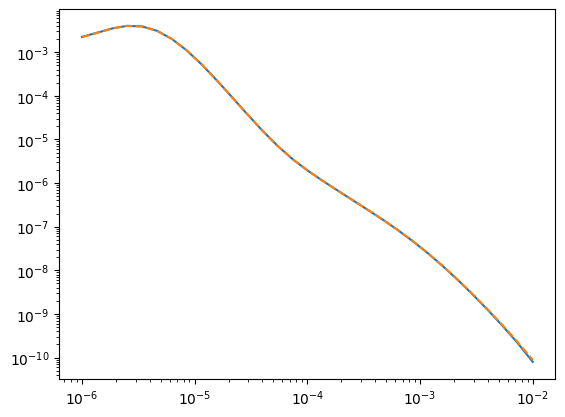

In [19]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(t0, dbdt0)
plt.loglog(t0, dbdt1, '--')